In [ ]:
'''Write in-depth model comparison reports that evaluate different classification algorithms (e.g., Logistic Regression, Random Forest, XGBoost) based on accuracy, fairness, and interpretability in admission outcomes.'''

'Generate detailed, structured reports that summarize admission model findings, highlighting key features, insights from data analysis, and recommendations for admission committees.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


In [3]:
# load dataset and prepare target variable
df = pd.read_csv('Adm.csv')
df['Admit'] = (df['Chance of Admit'] >= 0.70).astype(int)
print(df[['GRE Score', 'TOEFL Score', 'CGPA', 'Admit']].head())


   GRE Score  TOEFL Score  CGPA  Admit
0        337          118  9.65      1
1        324          107  8.87      1
2        316          104  8.00      0
3        322          110  8.67      1
4        314          103  8.21      0


In [4]:
# split features and scale data
feature_cols = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[feature_cols]
y = df['Admit']
X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(X, y, df, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("data scaling and split completed")


data scaling and split completed


In [5]:
# initialize classification models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}
print("models initialized:", list(models.keys()))


models initialized: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


In [6]:
# train models and evaluate accuracy metrics
metrics_list = []
for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        probs = model.predict_proba(X_test)[:, 1]
        
    metrics_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1_Score': f1_score(y_test, preds),
        'ROC_AUC': roc_auc_score(y_test, probs)
    })

metrics_df = pd.DataFrame(metrics_list)
print("=== accuracy performance metrics ===")
print(metrics_df)


=== accuracy performance metrics ===
                 Model  Accuracy  Precision    Recall  F1_Score   ROC_AUC
0  Logistic Regression     0.910   0.903509  0.936364  0.919643  0.980303
1        Random Forest     0.890   0.872881  0.936364  0.903509  0.960152
2    Gradient Boosting     0.905   0.895652  0.936364  0.915556  0.961818


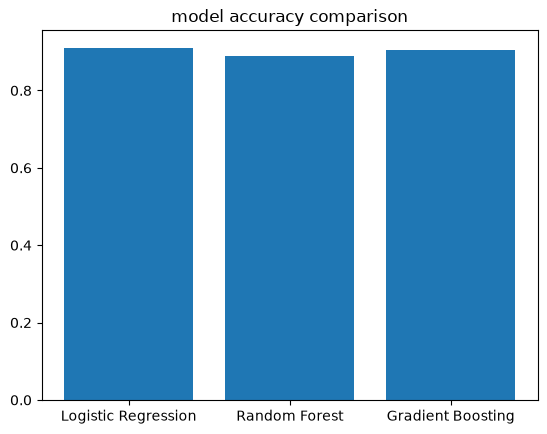

In [7]:
# plot model accuracy comparison
plt.figure()
plt.bar(metrics_df['Model'], metrics_df['Accuracy'])
plt.title('model accuracy comparison')
plt.show()


In [8]:
# evaluate fairness across algorithms by region
fairness_records = []
for name, model in models.items():
    preds = model.predict(X_test_scaled if name == 'Logistic Regression' else X_test)
    temp_df = df_test.copy()
    temp_df['pred'] = preds
    region_rates = temp_df.groupby('region')['pred'].mean()
    disparity = region_rates.max() - region_rates.min()
    fairness_records.append({
        'Model': name,
        'Selection Rate Disparity': disparity,
        'Avg Selection Rate': temp_df['pred'].mean()
    })

fairness_df = pd.DataFrame(fairness_records)
print("=== fairness evaluation by region ===")
print(fairness_df)


=== fairness evaluation by region ===
                 Model  Selection Rate Disparity  Avg Selection Rate
0  Logistic Regression                  0.454023               0.570
1        Random Forest                  0.517241               0.590
2    Gradient Boosting                  0.586207               0.575


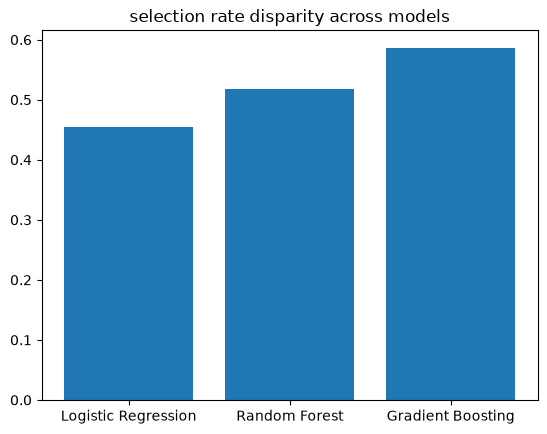

In [9]:
# plot fairness disparity across models
plt.figure()
plt.bar(fairness_df['Model'], fairness_df['Selection Rate Disparity'])
plt.title('selection rate disparity across models')
plt.show()


In [10]:
# evaluate interpretability and feature importance
interp_data = {
    'Feature': feature_cols,
    'LogReg_Coef': models['Logistic Regression'].coef_[0],
    'RF_Importance': models['Random Forest'].feature_importances_,
    'GB_Importance': models['Gradient Boosting'].feature_importances_
}
interp_df = pd.DataFrame(interp_data)
print("=== feature interpretability comparison ===")
print(interp_df)


=== feature interpretability comparison ===
             Feature  LogReg_Coef  RF_Importance  GB_Importance
0          GRE Score     1.317372       0.153125       0.079234
1        TOEFL Score     1.241212       0.121807       0.088517
2  University Rating     0.458650       0.036640       0.004938
3                SOP    -0.140649       0.054591       0.011371
4                LOR     1.109111       0.111838       0.056072
5               CGPA     4.079248       0.487137       0.733360
6           Research     0.845843       0.034862       0.026508


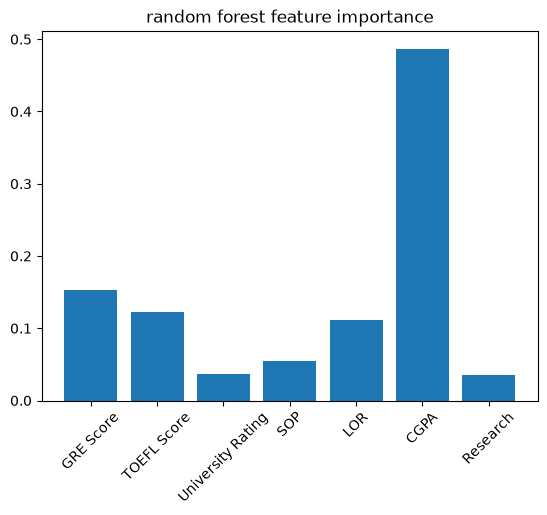

In [11]:
# plot feature importance for random forest
plt.figure()
plt.bar(feature_cols, models['Random Forest'].feature_importances_)
plt.xticks(rotation=45)
plt.title('random forest feature importance')
plt.show()


In [12]:
# generate comprehensive model comparison summary report
summary_report = pd.merge(metrics_df, fairness_df, on='Model')
summary_report['Interpretability'] = ['High (Coefficients)', 'Medium (Tree Gini)', 'Medium (Tree Gini)']
print("=== comprehensive model comparison report ===")
print(summary_report)


=== comprehensive model comparison report ===
                 Model  Accuracy  ...  Avg Selection Rate     Interpretability
0  Logistic Regression     0.910  ...               0.570  High (Coefficients)
1        Random Forest     0.890  ...               0.590   Medium (Tree Gini)
2    Gradient Boosting     0.905  ...               0.575   Medium (Tree Gini)

[3 rows x 9 columns]
